# Statistical Analysis (EDA)
Exploration behind the business story: distributions, category, city, age and monthly patterns.

In [1]:
import sys
sys.path.append('../scripts')
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import Image
df = pd.read_csv('../data/cleaned_sales_data.csv', parse_dates=['Order_Date'])
df.head()

,Order_ID,Order_Date,Customer_ID,Customer_Name,Age,Gender,City,Product,Category,Quantity,Unit_Price,Total_Sales,Age_Missing,Order_ID_Reused,Month,Age_Group
0,ORD100002,2025-02-25,CUST5529,Customer_227,30.0,Female,Bengaluru,Rice,Grocery,7,2829.77,19808.39,False,False,2025-02,26-35
1,ORD100003,2025-10-14,CUST3127,Customer_182,63.0,Male,Bengaluru,Book,Education,5,27906.16,139530.80,False,False,2025-10,56-65
2,ORD100004,2025-05-13,CUST8887,Customer_487,62.0,Female,Bengaluru,Book,Education,8,37491.06,299928.48,False,False,2025-05,56-65
3,ORD100005,2025-12-02,CUST2515,Customer_470,65.0,Female,Kolkata,Mobile,Electronics,9,28541.36,256872.24,False,False,2025-12,56-65
4,ORD100006,2025-11-20,CUST4796,Customer_380,44.0,Male,Bengaluru,Rice,Grocery,10,14036.59,140365.90,False,False,2025-11,36-45


In [2]:
df[['Quantity','Unit_Price','Total_Sales','Age']].describe().round(1)

,Quantity,Unit_Price,Total_Sales,Age
count,1000.0,1000.0,1000.0,1000.0
mean,5.4,25486.8,139399.4,41.4
std,2.8,14179.4,114100.1,13.7
min,1.0,145.8,437.3,18.0
25%,3.0,13895.7,47066.6,30.0
50%,5.0,25398.7,108594.0,41.0
75%,8.0,37512.4,203722.9,53.0
max,10.0,49997.5,493677.5,65.0


## Order value is right-skewed, so medians matter

skew 0.99 | mean 139399 | median 108594


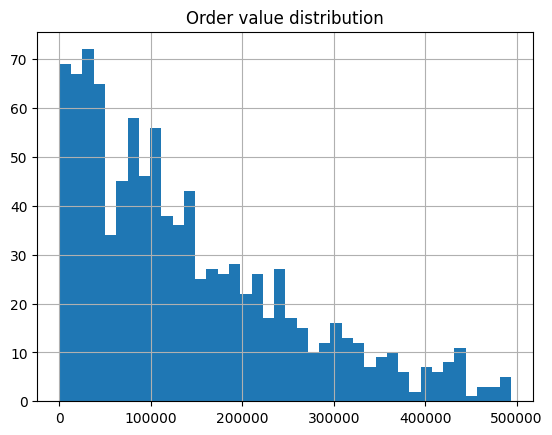

In [3]:
print('skew', round(df.Total_Sales.skew(),2), '| mean', round(df.Total_Sales.mean()), '| median', round(df.Total_Sales.median()))
df.Total_Sales.hist(bins=40); plt.title('Order value distribution'); plt.show()

## Revenue and average order value by category

In [4]:
df.groupby('Category').Total_Sales.agg(['count','sum','mean','median']).sort_values('sum', ascending=False).round(0)

,count,sum,mean,median
Category,,,,
Electronics,354,50778582.0,143442.0,114521.0
Education,178,25031689.0,140627.0,108469.0
Grocery,153,22231711.0,145305.0,109238.0
Furniture,159,21521561.0,135356.0,99839.0
Fashion,156,19835896.0,127153.0,101570.0


Electronics leads on revenue because it has the most orders (two products). Is the difference in *average order value* across categories real?

In [5]:
groups = [g.Total_Sales for _, g in df.groupby('Category')]
print(stats.f_oneway(*groups))
print(stats.kruskal(*groups))

F_onewayResult(statistic=np.float64(0.7171167721714614), pvalue=np.float64(0.5802864995733577))
KruskalResult(statistic=np.float64(2.0066349326366435), pvalue=np.float64(0.7345384569224721))


## City, age group and month

In [6]:
print(df[df.City!='Unknown'].groupby('City').Total_Sales.agg(['sum','mean','count']).sort_values('sum', ascending=False).round(0))
print(df.groupby('Age_Group').Total_Sales.agg(['sum','mean','count']).round(0))
monthly = pd.read_csv('../data/monthly_sales.csv'); monthly[monthly.Complete_Month]

                  sum      mean  count
City                                  
Patna      19285967.0  142859.0    135
Kolkata    18884350.0  141988.0    133
Bengaluru  18773574.0  153882.0    122
Mumbai     18757050.0  143184.0    131
Hyderabad  17166767.0  137334.0    125
Delhi      16097079.0  128777.0    125
Pune       14513176.0  146598.0     99
Gaya       14380859.0  122913.0    117
                  sum      mean  count
Age_Group                             
18-25      22284097.0  141039.0    158
26-35      29632337.0  135307.0    219
36-45      31533246.0  141405.0    223
46-55      28216509.0  139686.0    202
56-65      27733251.0  140067.0    198


,Month,Revenue,Orders,Avg_Order_Value,Complete_Month
0,2025-01,10096190.73,76,132844.614868,True
1,2025-02,11511181.46,86,133850.947209,True
2,2025-03,13059899.94,89,146740.448764,True
3,2025-04,12222700.17,80,152783.752125,True
4,2025-05,10984689.25,85,129231.638235,True
5,2025-06,12912332.64,83,155570.272771,True
6,2025-07,11746226.80,83,141520.804819,True
7,2025-08,9448471.22,75,125979.616267,True
8,2025-09,9179896.29,79,116201.218861,True
9,2025-10,12500936.50,84,148820.672619,True


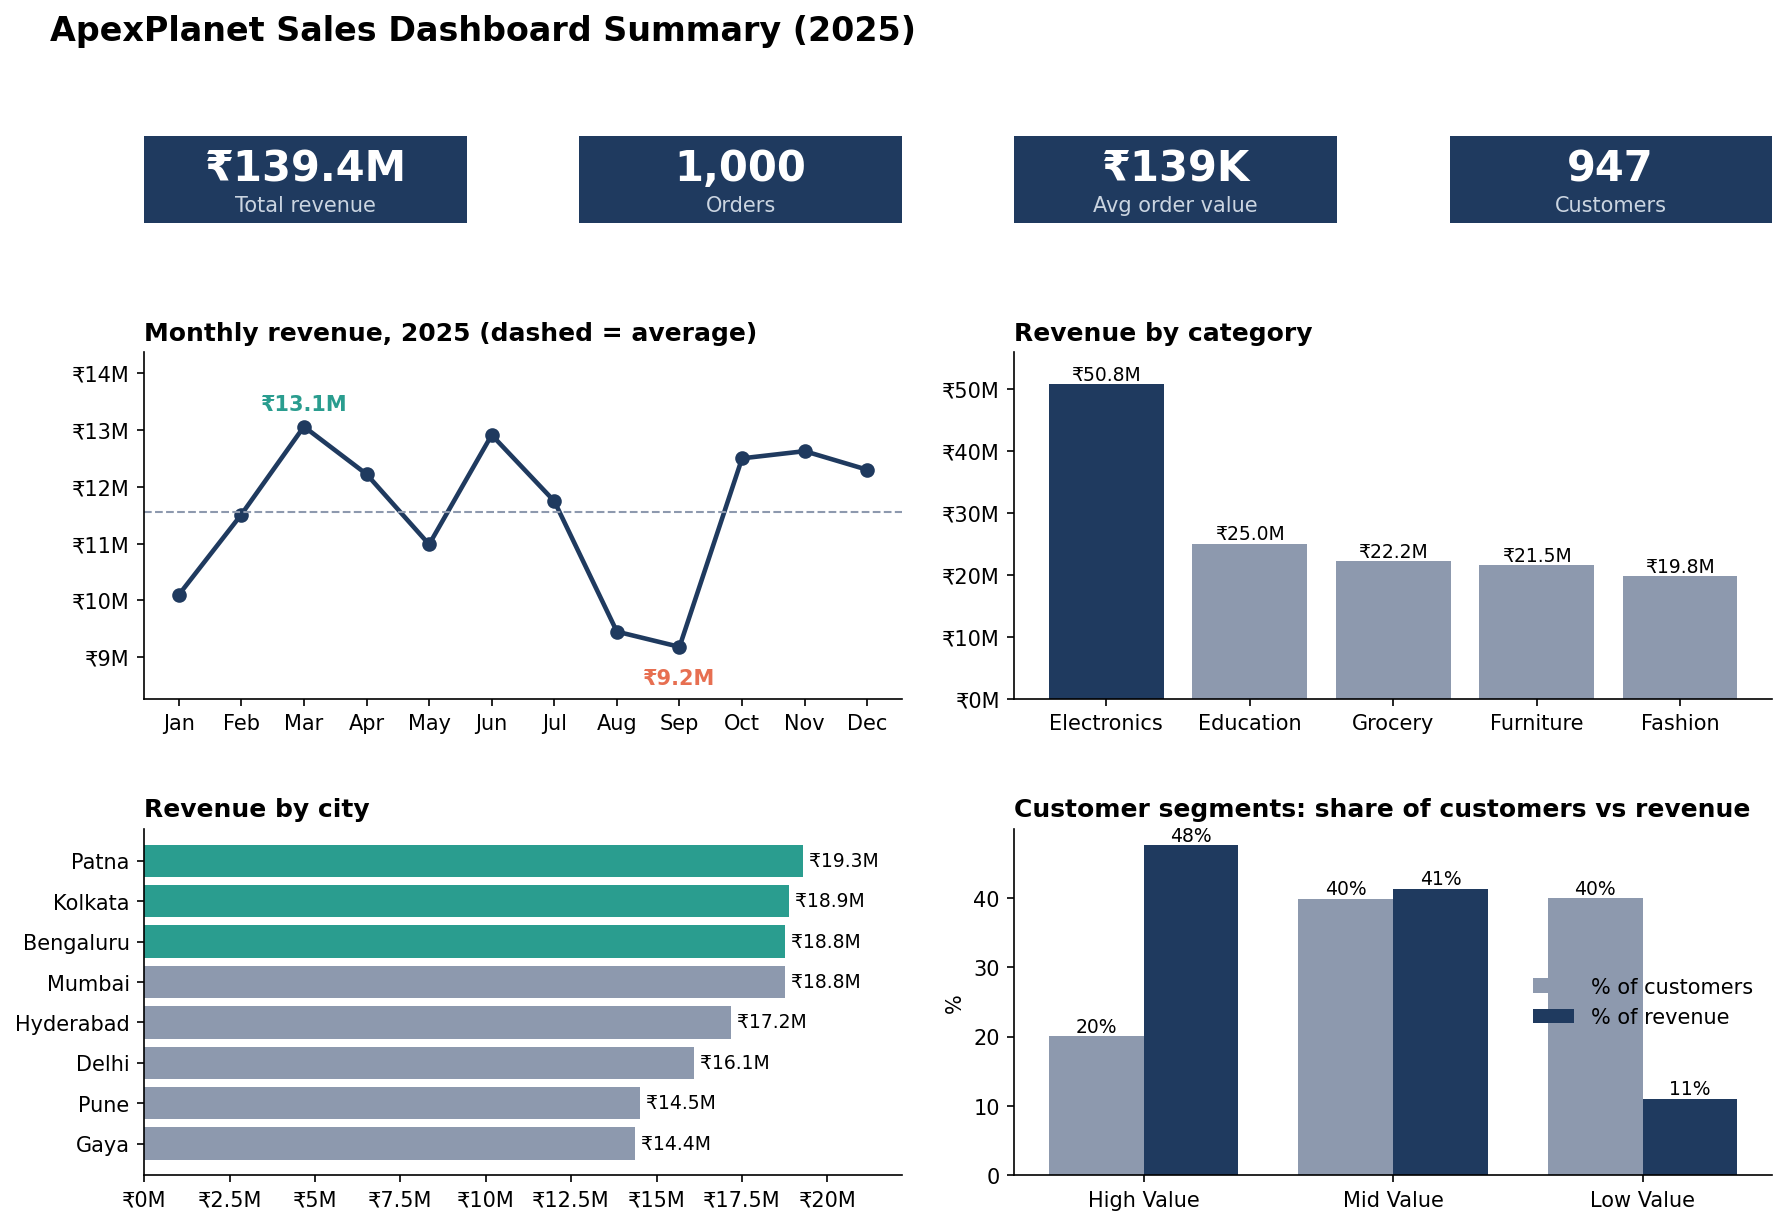

In [7]:
Image('../charts/dashboard_summary.png')